In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
np.random.seed(28)
X = np.random.rand(100,1) - 0.5
y = 3*X[:,0]**2 + 0.05 * np.random.randn(100)

In [5]:
df = pd.DataFrame()
df['X'] = X.reshape(100)
df['y'] = y
df.head()

,X,y
0,0.229014,0.233054
1,0.061240,-0.057468
2,-0.375033,0.400811
3,-0.102408,0.028938
4,0.281308,0.274147


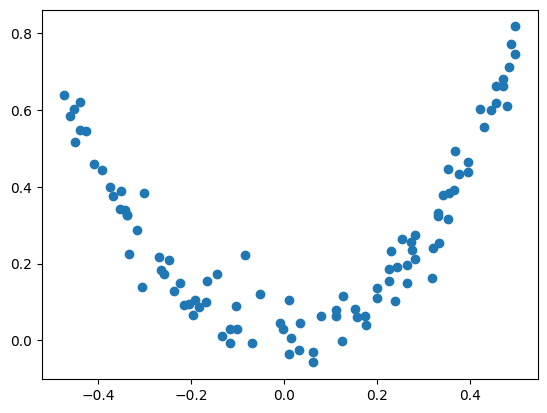

In [6]:
plt.scatter(df['X'],df['y'])

In [7]:
df['pred1'] = df['y'].mean()
df.head()

,X,y,pred1
0,0.229014,0.233054,0.273744
1,0.061240,-0.057468,0.273744
2,-0.375033,0.400811,0.273744
3,-0.102408,0.028938,0.273744
4,0.281308,0.274147,0.273744


In [8]:
df['res1'] = df['y'] - df['pred1']
df.head()

,X,y,pred1,res1
0,0.229014,0.233054,0.273744,-0.040690
1,0.061240,-0.057468,0.273744,-0.331212
2,-0.375033,0.400811,0.273744,0.127067
3,-0.102408,0.028938,0.273744,-0.244806
4,0.281308,0.274147,0.273744,0.000403


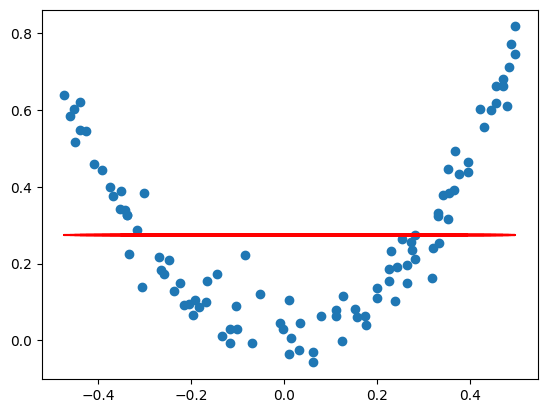

In [15]:
plt.scatter(df['X'], df['y'])
plt.plot(df['X'],df['pred1'], 'r')

In [16]:
from sklearn.tree import DecisionTreeRegressor
tree1 = DecisionTreeRegressor(max_leaf_nodes=8)

In [17]:
tree1.fit(df['X'].values.reshape(100,1),df['res1'].values)

DecisionTreeRegressor(max_leaf_nodes=8)

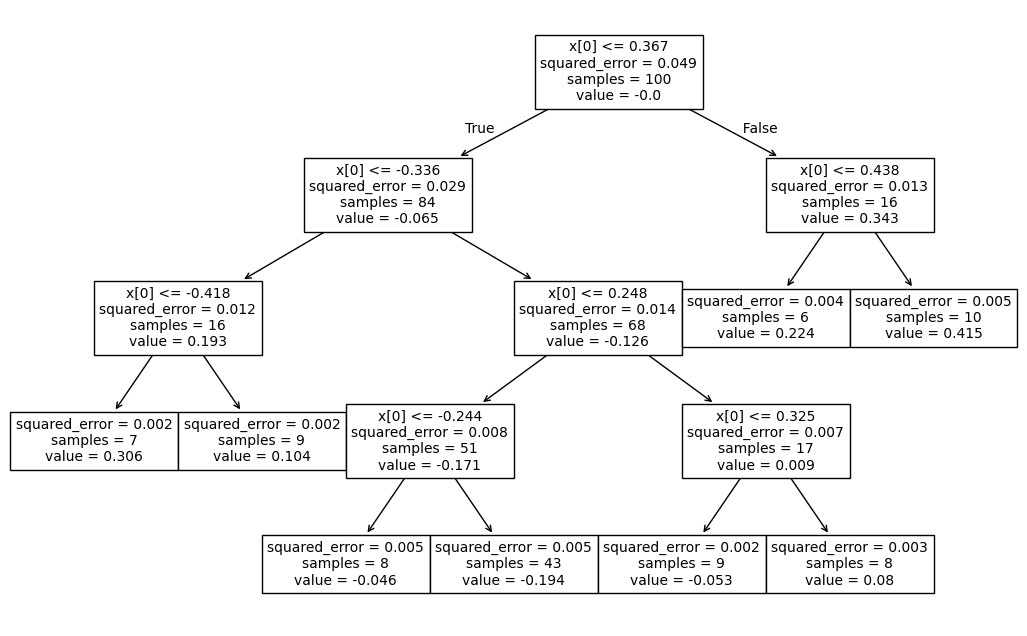

In [24]:
from sklearn.tree import plot_tree
plt.figure(figsize=(13,8))
plot_tree(tree1)
plt.show()

In [25]:
X_test= np.linspace(-0.5,0.5,500)

In [26]:
y_pred = df['y'].mean() + tree1.predict(X_test.reshape(500,1))

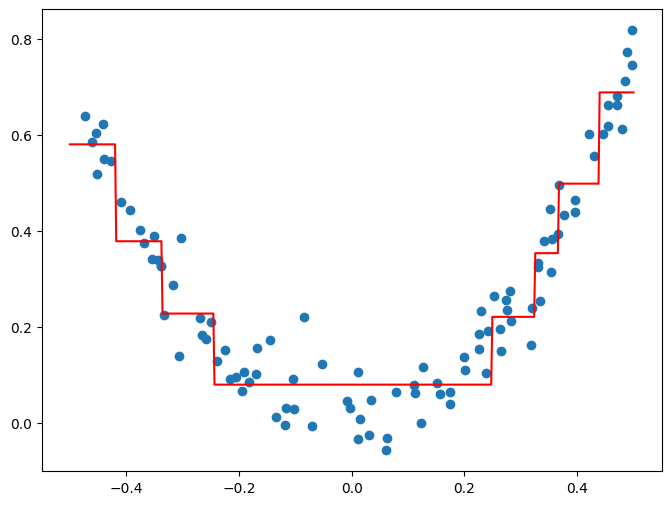

In [29]:
plt.figure(figsize=(8,6))
plt.plot(X_test,y_pred,color='red')
plt.scatter(df['X'],df['y'])

In [30]:
df['pred2'] = df['y'].mean() + tree1.predict(df['X'].values.reshape(100,1))

In [31]:
df.head()

,X,y,pred1,res1,pred2
0,0.229014,0.233054,0.273744,-0.040690,0.079292
1,0.061240,-0.057468,0.273744,-0.331212,0.079292
2,-0.375033,0.400811,0.273744,0.127067,0.378097
3,-0.102408,0.028938,0.273744,-0.244806,0.079292
4,0.281308,0.274147,0.273744,0.000403,0.220528


In [32]:
df['res2'] = df['y'] - df['pred2']
df.head()

,X,y,pred1,res1,pred2,res2
0,0.229014,0.233054,0.273744,-0.040690,0.079292,0.153762
1,0.061240,-0.057468,0.273744,-0.331212,0.079292,-0.136760
2,-0.375033,0.400811,0.273744,0.127067,0.378097,0.022714
3,-0.102408,0.028938,0.273744,-0.244806,0.079292,-0.050354
4,0.281308,0.274147,0.273744,0.000403,0.220528,0.053619


In [33]:
tree2 = DecisionTreeRegressor(max_leaf_nodes=8)

In [34]:
tree2.fit(df['X'].values.reshape(100,1),df['res2'].values)

DecisionTreeRegressor(max_leaf_nodes=8)

In [35]:
y_pred = df['y'].mean() + sum(regressor.predict(X_test.reshape(-1,1)) for regressor in [tree1,tree2])

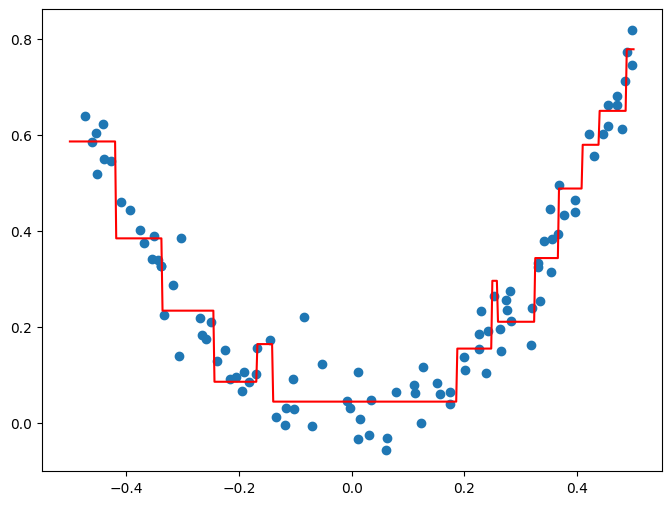

In [36]:
plt.figure(figsize=(8,6))
plt.plot(X_test,y_pred,color='red')
plt.scatter(df['X'],df['y'])

In [37]:
def gradient_boost(X,y,number,lr,count=1,regs=[],foo=None):

  if number == 0:
    return 
  else:
    # do gradient boosting

    if count > 1:
      y = y - regs[-1].predict(X)
    else:
      foo = y

    tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
    tree_reg.fit(X, y)

    regs.append(tree_reg)

    x1 = np.linspace(-0.5, 0.5, 500)
    y_pred = sum(lr * regressor.predict(x1.reshape(-1, 1)) for regressor in regs)

    print(number)
    plt.figure()
    plt.plot(x1, y_pred, linewidth=2)
    plt.plot(X[:, 0], foo,"r.")
    plt.show()

    gradient_boost(X,y,number-1,lr,count+1,regs,foo=foo)


5


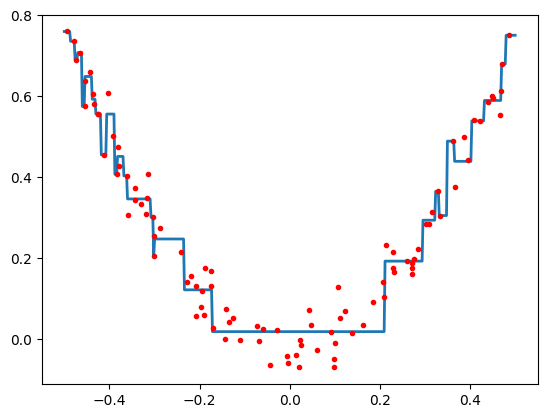

4


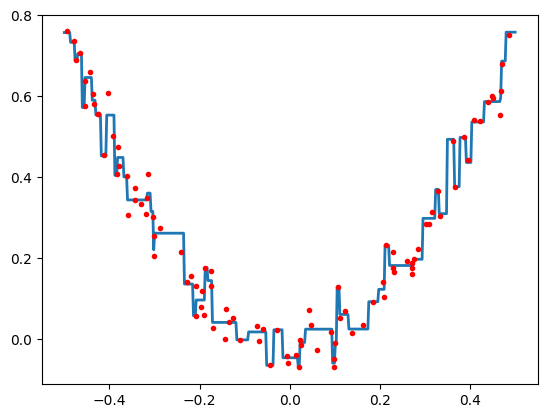

3


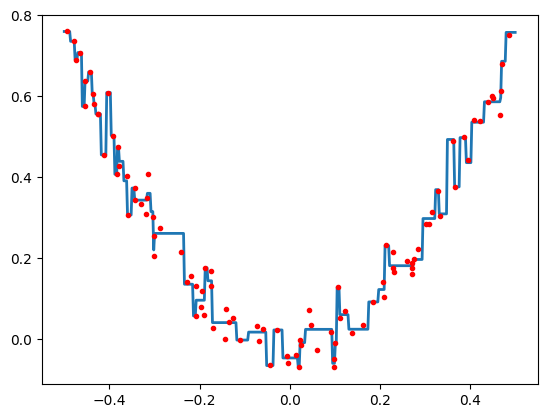

2


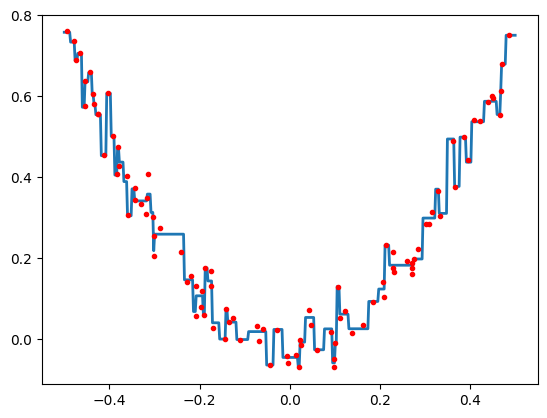

1


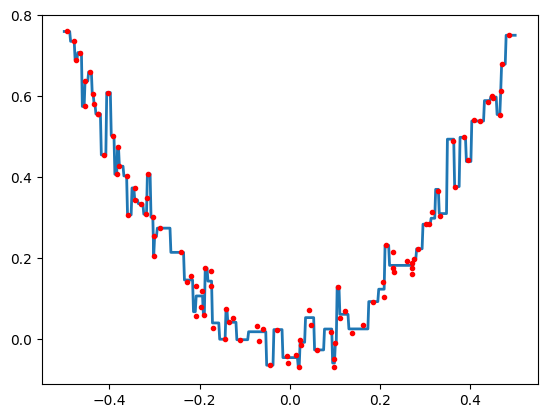

In [38]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)
gradient_boost(X,y,5,lr=1)